# Project #23H — Red Queen Dynamics in Host-Parasite Coevolution
### Does coevolution automatically produce perpetual oscillation, or only under specific conditions?

**Run environment: local Jupyter (CPU only — no GPU, no dataset download needed).**

**What this notebook does:** builds two real, standard discrete-generation host-parasite coevolutionary
models — matching-allele (MA) and gene-for-gene (GFG) — and determines, under explicit swept parameters,
exactly when each one produces sustained Red Queen-style oscillation versus settling to a stable
equilibrium. Classification is done objectively via a spectral method that is itself validated against
synthetic ground-truth signals with known correct answers before being trusted on the real simulated
coevolutionary dynamics — not read off a trajectory plot by eye.

**Read `PROJECT_NARRATIVE.md` first, then `WORKFLOW.md`, before doing this build.**

## Step 0 — Environment setup

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)


numpy: 2.4.6


## Step 1 — The matching-allele (MA) coevolution model

**Biological reason:** a parasite genotype can only successfully exploit the matching host genotype (a
simplified model of specific immune recognition/evasion). Host genotype `i`'s fitness falls with the
frequency of the matching parasite genotype; parasite genotype `i`'s fitness rises with the frequency of
the matching host genotype — a symmetric, lagged negative-feedback loop structurally similar to predator-
prey cycling.

In [11]:
def ma_step(H, P, sH, sP, muH, muP, n):
    wH = np.clip(1 - sH*P, 1e-6, None)
    wP = np.clip(1 + sP * H, 1e-6, None)
    H_next = H*wH/np.sum(H*wH)
    P_next = P*wP / np.sum(P*wP)
    H_next = (1-muH) * H_next + muH * np.ones(n) / n
    P_next = (1-muP) * P_next + muP * np.ones(n) / n
    return H_next, P_next

rng = np.random.default_rng(0)
n = 2
H = rng.dirichlet(np.ones(n))
P = rng.dirichlet(np.ones(n))

traceH_sanity = [H[0]]
for _ in range(20):
    H, P = ma_step(H,P,0.8,0.8,0.01,0.01,n)
    traceH_sanity.append(H[0])
    assert abs(np.sum(H) - 1) < 1e-9 and abs(np.sum(P) - 1) < 1e-9
    assert np.all(H >= -1e-9) and np.all(P >= -1e-9)

print("MA sanity check: frequency validity OK across 20 generations")
print("H[0] trace:", np.round(traceH_sanity, 4))


MA sanity check: frequency validity OK across 20 generations
H[0] trace: [0.4001 0.1735 0.0682 0.0321 0.0212 0.0198 0.0248 0.0405 0.083  0.1952
 0.434  0.7249 0.8981 0.9608 0.9797 0.9846 0.9839 0.9782 0.9626 0.9202
 0.8067]


## Step 2 — The gene-for-gene (GFG) coevolution model

**Biological reason:** host allele `R` resists parasite allele `v` (avirulent) specifically, but parasite
allele `V` (virulent) overcomes ANY host — a fundamentally asymmetric matchup (one genotype beats
everything, unlike MA's symmetric genotype-vs-genotype matching). `R` carries a resistance cost `cR` even
when not needed; `V` carries a virulence cost `cV` even when unnecessary — real costs that can maintain a
polymorphic equilibrium instead of a one-sided arms race to fixation.

In [12]:
def gfg_step(hR, pV, cR, cV, sH, bP, muH, muP):
    hr = 1-hR
    pv = 1-pV
    wH_R = 1 - cR - sH * (1-pv)
    wH_r = 1 - sH
    wP_V = 1 + bP - cV
    wP_v = 1 + bP * (1-hR)

    WbarH = hR * wH_R + hr * wH_r
    WbarP = pV * wP_V + pv * wP_v

    hR_next = hR * wH_R / WbarH
    pV_next = pV * wP_V/ WbarP

    hR_next = (1-muH) * hR_next + muH * 0.5
    pV_next = (1-muP) * pV_next + muP * 0.5
    return hR_next, pV_next

hR, pV = 0.3, 0.3
traceH_gfg_sanity = [hR]
for _ in range(20):
    hR, pV = gfg_step(hR, pV, 0.1, 0.1, 0.5, 0.5, 0.01, 0.01)
    traceH_gfg_sanity.append(hR)
    assert -1e-9 <= hR <= 1 + 1e-9 and -1e-9 <= pV <= 1 + 1e-9

print("GFG sanity check: frequency validity OK across 20 generations")
print("hR trace:", np.round(traceH_gfg_sanity, 4))


GFG sanity check: frequency validity OK across 20 generations
hR trace: [0.3    0.3924 0.4905 0.5857 0.6699 0.7389 0.7915 0.8296 0.8557 0.8725
 0.8819 0.8856 0.8845 0.8792 0.87   0.8569 0.84   0.8193 0.7946 0.766
 0.7336]


## Step 3 — The spectral oscillation/equilibrium classifier, validated first

**Mathematical reason:** a genuinely sustained cycle and a slowly-damping transient oscillation can look
similar on a short trajectory plot, so eyeballing isn't a rigorous classification. The real, standard tool
is spectral (periodogram) analysis on a late-time, detrended window — but any such tool needs validating
against synthetic cases with KNOWN ground truth before being trusted on cases where the true answer isn't
known in advance.

In [13]:
def classify_dynamics(trace, burn_frac=0.6, power_threshold=0.2, var_threshold=1e-8):
    burn_in = int(len(trace) * burn_frac)
    x_tail = trace[burn_in:]
    if np.var(x_tail) < var_threshold:
        return False, 0.0, 0.0  # already converged -> equilibrium, high confidence
    x = signal.detrend(x_tail, type='linear')
    freqs, psd = signal.periodogram(x)
    freqs, psd = freqs[1:], psd[1:]
    total_power = np.sum(psd)
    if total_power < 1e-12:
        return False, 0.0, 0.0
    peak_idx = np.argmax(psd)
    peak_power_fraction = psd[peak_idx] / total_power
    dominant_freq = freqs[peak_idx]
    is_oscillating = peak_power_fraction > power_threshold
    return is_oscillating, dominant_freq, peak_power_fraction

N = 1500
t = np.arange(N)
rng_v = np.random.default_rng(1)
sine = 0.5 + 0.3*np.sin(2*np.pi*t/20) + 0.01*rng_v.normal(size=N)
decay = 0.9 - 0.4*np.exp(-t/30) + 0.01*np.random.default_rng(2).normal(size=N)
noise = 0.5 + 0.05*np.random.default_rng(3).normal(size=N)
trend = 0.25 + 0.01*(1 - np.exp(-t/400)) + 0.001*np.random.default_rng(4).normal(size=N)

print("Pure sine (expect True):           ", classify_dynamics(sine)[0])
print("Exponential decay (expect False):  ", classify_dynamics(decay)[0])
print("Pure noise (expect False):         ", classify_dynamics(noise)[0])
print("Slow monotonic trend (expect False):", classify_dynamics(trend)[0])


Pure sine (expect True):            True
Exponential decay (expect False):   False
Pure noise (expect False):          False
Slow monotonic trend (expect False): False


## Step 4 — Does the expected MA-vs-GFG contrast actually appear?

In [14]:
def run_ma(s, mu, N=1500, seed=0):
    rng_r = np.random.default_rng(seed)
    n = 2
    H = rng_r.dirichlet(np.ones(n))
    P = rng_r.dirichlet(np.ones(n))
    trace = [H[0]]
    for _ in range(N):
        H, P = ma_step(H, P, s, s, mu, mu, n)
        trace.append(H[0])
    return np.array(trace)

def run_gfg(cR, cV, sH=0.5, bP=0.5, mu=0.01, N=1500):
    hR, pV = 0.3, 0.3
    trace = [hR]
    for _ in range(N):
        hR, pV = gfg_step(hR, pV, cR, cV, sH, bP, mu, mu)
        trace.append(hR)
    return np.array(trace)

trace_ma_rep = run_ma(0.8, 0.01)
trace_gfg_rep = run_gfg(0.1, 0.1)

osc_ma, freq_ma, power_ma = classify_dynamics(trace_ma_rep)
osc_gfg, freq_gfg, power_gfg = classify_dynamics(trace_gfg_rep)

print(f"MA (s=0.8, mu=0.01):   oscillating={osc_ma}   power_frac={power_ma:.3f}")
print(f"GFG (cR=cV=0.1):       oscillating={osc_gfg}   power_frac={power_gfg:.3f}")


MA (s=0.8, mu=0.01):   oscillating=True   power_frac=0.951
GFG (cR=cV=0.1):       oscillating=False   power_frac=0.000


## Step 5 — MA sweep: selection strength and mutation rate

In [15]:
s_values = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8]
ma_s_rows = []
for s in s_values:
    tr = run_ma(s, 0.01)
    osc, freq, power = classify_dynamics(tr)
    ma_s_rows.append({"s": s, "oscillating": osc, "power_frac": power})
    print(f"s={s:.2f}  oscillating={osc}  power_frac={power:.3f}")

ma_s_df = pd.DataFrame(ma_s_rows)

mu_values = [0.001, 0.01, 0.05, 0.1, 0.2, 0.4]
ma_mu_rows = []
for mu in mu_values:
    tr = run_ma(0.8, mu)
    osc, freq, power = classify_dynamics(tr)
    ma_mu_rows.append({"mu": mu, "oscillating": osc, "power_frac": power})
    print(f"mu={mu:.3f}  oscillating={osc}  power_frac={power:.3f}")

ma_mu_df = pd.DataFrame(ma_mu_rows)


s=0.05  oscillating=False  power_frac=0.000
s=0.10  oscillating=False  power_frac=0.000
s=0.20  oscillating=True  power_frac=0.406
s=0.40  oscillating=True  power_frac=0.595
s=0.60  oscillating=True  power_frac=0.697
s=0.80  oscillating=True  power_frac=0.951
mu=0.001  oscillating=True  power_frac=0.500
mu=0.010  oscillating=True  power_frac=0.951
mu=0.050  oscillating=True  power_frac=0.461
mu=0.100  oscillating=False  power_frac=0.000
mu=0.200  oscillating=False  power_frac=0.000
mu=0.400  oscillating=False  power_frac=0.000


## Step 6 — GFG sweep: cost parameters

In [16]:
c_values = [0.001, 0.01, 0.05, 0.1, 0.3, 0.5]
gfg_c_rows = []
for c in c_values:
    tr = run_gfg(c,c)
    osc, freq, power = classify_dynamics(tr)
    gfg_c_rows.append({"c": c, "oscillating": osc, "power_frac": power, "final_hR": tr[-1]})
    print(f"c={c:.3f}  oscillating={osc}  power_frac={power:.3f}  final_hR={tr[-1]:.4f}")

gfg_c_df = pd.DataFrame(gfg_c_rows)


c=0.001  oscillating=False  power_frac=0.000  final_hR=0.7821
c=0.010  oscillating=False  power_frac=0.000  final_hR=0.6106
c=0.050  oscillating=False  power_frac=0.000  final_hR=0.2521
c=0.100  oscillating=False  power_frac=0.000  final_hR=0.2579
c=0.300  oscillating=True  power_frac=0.674  final_hR=0.7255
c=0.500  oscillating=False  power_frac=0.000  final_hR=0.2112


## Step 7 — Direct comparison: does MA favor Red Queen dynamics more than GFG?

In [17]:
ma_osc_fraction = ma_s_df["oscillating"].mean()
gfg_osc_fraction = gfg_c_df["oscillating"].mean()
print(f"MA: fraction of swept s-values showing oscillation:  {ma_osc_fraction:.2f}")
print(f"GFG: fraction of swept c-values showing oscillation: {gfg_osc_fraction:.2f}")

gfg_oscillating_rows = gfg_c_df[gfg_c_df["oscillating"]]
if len(gfg_oscillating_rows) > 0:
    c_edge = gfg_oscillating_rows.iloc[0]["c"]
    print(f"\nGFG edge case found at c={c_edge}. Re-running at N=5000 to confirm genuine sustained oscillation...")
    tr_long = run_gfg(c_edge, c_edge, N=5000)
    osc_long, freq_long, power_long = classify_dynamics(tr_long, burn_frac=0.6)
    var_last_500 = np.var(tr_long[-500:])
    var_last_2000 = np.var(tr_long[-2000:])
    print(f"At N=5000: oscillating={osc_long}  var(last 500)={var_last_500:.5f}  var(last 2000)={var_last_2000:.5f}")
else:
    print("\nNo GFG edge case found in this sweep.")


MA: fraction of swept s-values showing oscillation:  0.67
GFG: fraction of swept c-values showing oscillation: 0.17

GFG edge case found at c=0.3. Re-running at N=5000 to confirm genuine sustained oscillation...
At N=5000: oscillating=True  var(last 500)=0.01389  var(last 2000)=0.01386


## Step 8 — Hero figures + CSV export

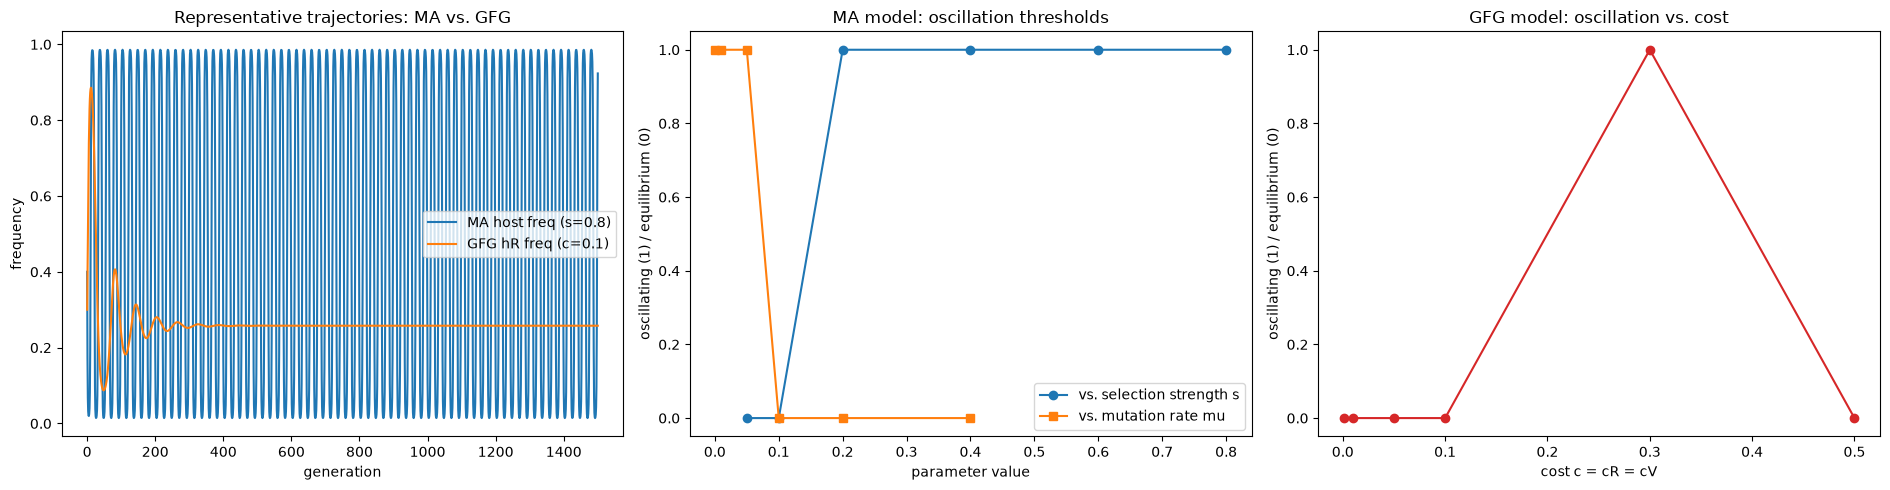

Exported results/hero_red_queen.png, results/ma_selection_sweep.csv,
results/ma_mutation_sweep.csv, results/gfg_cost_sweep.csv


In [18]:
import os
os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(trace_ma_rep, label="MA host freq (s=0.8)", color="tab:blue")
axes[0].plot(trace_gfg_rep, label="GFG hR freq (c=0.1)", color="tab:orange")
axes[0].set_xlabel("generation")
axes[0].set_ylabel("frequency")
axes[0].set_title("Representative trajectories: MA vs. GFG")
axes[0].legend()

axes[1].plot(ma_s_df["s"], ma_s_df["oscillating"].astype(int), marker="o", label="vs. selection strength s")
axes[1].plot(ma_mu_df["mu"], ma_mu_df["oscillating"].astype(int), marker="s", label="vs. mutation rate mu")
axes[1].set_xlabel("parameter value")
axes[1].set_ylabel("oscillating (1) / equilibrium (0)")
axes[1].set_title("MA model: oscillation thresholds")
axes[1].legend()

axes[2].plot(gfg_c_df["c"], gfg_c_df["oscillating"].astype(int), marker="o", color="tab:red")
axes[2].set_xlabel("cost c = cR = cV")
axes[2].set_ylabel("oscillating (1) / equilibrium (0)")
axes[2].set_title("GFG model: oscillation vs. cost")

plt.tight_layout()
plt.savefig("results/hero_red_queen.png", dpi=150)
plt.show()

ma_s_df.to_csv("results/ma_selection_sweep.csv", index=False)
ma_mu_df.to_csv("results/ma_mutation_sweep.csv", index=False)
gfg_c_df.to_csv("results/gfg_cost_sweep.csv", index=False)
print("Exported results/hero_red_queen.png, results/ma_selection_sweep.csv,")
print("results/ma_mutation_sweep.csv, results/gfg_cost_sweep.csv")
